In [35]:
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
from PIL import Image
from pprint import pprint

img_dir = "/TP2_IA/Data/CT/"

In [36]:
class CovidDataset(Dataset):
    def __init__(self, covid_txt, non_covid_txt , transform=None): #covid_text chemin vers dataset covid

        self.transform = transform

        with open(covid_txt, "r") as f:
            lines = f.readlines()

        covid_data = [img_dir+"CT_COVID/"+line.strip() for line in lines]
        covid_labels = [1 for _ in lines]

        with open(non_covid_txt, "r") as f:
            non_covid_lines = f.readlines()

        non_covid_data = [img_dir+"CT_NonCOVID/"+line.strip() for line in non_covid_lines]
        non_covid_labels = [0 for _ in non_covid_lines]

        self.data = covid_data+non_covid_data
        self.img_labels = covid_labels+non_covid_labels

    def __len__(self):
        return self.data.__len__()

    def __getitem__(self, idx):
        img_path = self.data[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.img_labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label


transformer = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

trainset = CovidDataset(img_dir + "trainCT_COVID.txt", img_dir + "trainCT_NonCOVID.txt", transform=transformer)

valset = CovidDataset(img_dir +"valCT_COVID.txt", img_dir + "valCT_NonCOVID.txt", transform=transformer)

testset = CovidDataset(img_dir +"testCT_COVID.txt", img_dir + "testCT_NonCOVID.txt", transform=transformer)

print(len(trainset), len(valset), len(testset))
img, label = trainset[0]
print(img.shape, label)

425 118 203
torch.Size([3, 256, 256]) 1


In [38]:
batch_size = 64

train_dataloader = DataLoader(trainset, batch_size=batch_size, drop_last=False, shuffle=True)
val_dataloader = DataLoader(valset, batch_size=batch_size, drop_last=False, shuffle=False)
test_dataloader = DataLoader(testset, batch_size=batch_size, drop_last=False, shuffle=True)

print("Train DataLoader")
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")

print("\nValidation DataLoader")
for X, y in val_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")

print("\nTest DataLoader")
for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")

Train DataLoader
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([41, 3, 256, 256])
Shape of y: torch.Size([41]) torch.int64

Validation DataLoader
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([54, 3, 256, 256])
Shape of y: torch.Size([54]) torch.int64

Test DataLoader
Shape of X [N, C, H, W]: torch.Size([64, 3, 256, 256])
Shape of y: torch.Size([

In [42]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc = nn.Linear(64 * 64 * 64, 2)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.pool(x)

        x = x.flatten(start_dim=1)
        x = self.fc(x)
        return x

In [45]:
def train(model, dataloader, loss_fn, optimizer, epoch, device):
    model.train()
    loss_total = 0

    for X, y in tqdm(dataloader):
        X, y = X.to(device), y.to(device)

        pred = model(X)
        loss = loss_fn(pred, y)
        loss_total += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    loss_total /= len(dataloader)          # moyenne par batch
    print(f"[train] epoch {epoch:>3d}  loss: {loss_total:>7f}")
    return loss_total


def test(model, dataloader, loss_fn, epoch, device):
    model.eval()
    loss_total = 0

    with torch.no_grad():                   # pas de gradient en évaluation
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss_total += loss_fn(pred, y).item()

    loss_total /= len(dataloader)
    print(f"[val]   epoch {epoch:>3d}  loss: {loss_total:>7f}")
    return loss_total

100%|██████████| 7/7 [00:40<00:00,  5.76s/it]


[train] epoch   1  loss: 1.841719
[val]   epoch   1  loss: 0.747361


100%|██████████| 7/7 [00:38<00:00,  5.50s/it]


[train] epoch   2  loss: 0.633660
[val]   epoch   2  loss: 0.675159


100%|██████████| 7/7 [00:36<00:00,  5.20s/it]


[train] epoch   3  loss: 0.545235
[val]   epoch   3  loss: 0.686838


... (10 outputs left out)

100%|██████████| 7/7 [00:36<00:00,  5.22s/it]


[train] epoch   9  loss: 0.190687
[val]   epoch   9  loss: 0.918258


100%|██████████| 7/7 [00:36<00:00,  5.17s/it]


[train] epoch  10  loss: 0.129152
[val]   epoch  10  loss: 0.986212


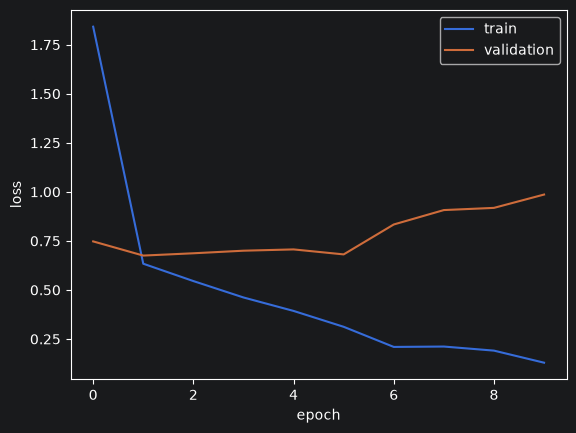

In [47]:
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

device = "cpu"

# modèle
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
epochs = 10

train_losses, val_losses = [], []
best_val = float("inf")

for epoch in range(1, epochs + 1):
    train_losses.append(train(model, train_dataloader, loss_fn, optimizer, epoch, device))
    val_loss = test(model, val_dataloader, loss_fn, epoch, device)
    val_losses.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best_model.pth")

# courbes
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()